In [2]:
import torch
import torchvision
import torch.nn as nn
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu128
Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


Original image size: (496, 512)
Mask shape: (512, 512)
Mask class IDs: [0 1 2 3 4 5]


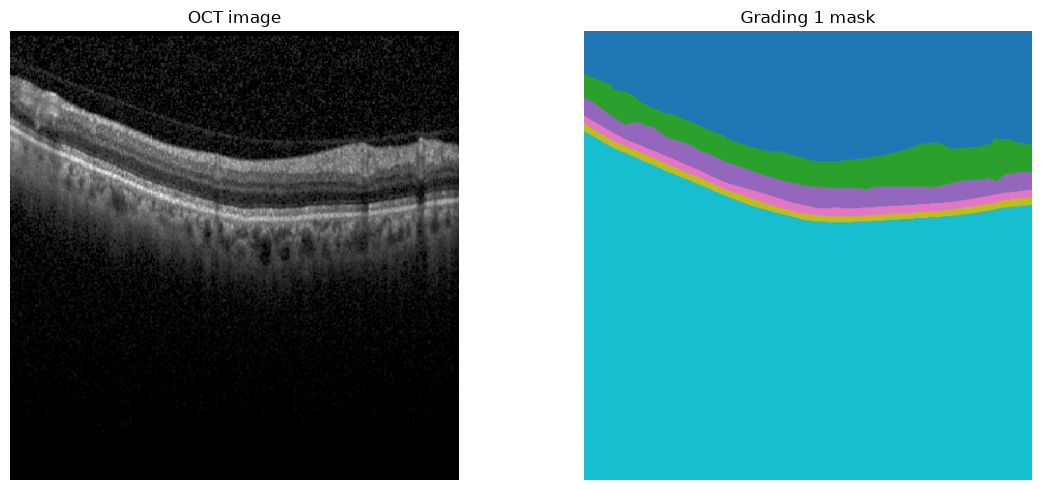

In [ ]:
from pathlib import Path
import csv
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

data_root = Path(r"C:\Users\asus\Documents\OCT5k\OCT5k\OCT5k")
scripts_dir = data_root / "Scripts"

with open(scripts_dir / "paths" / "manual_paths.csv", newline="") as file:
    prepared_path, original_path = next(csv.reader(file))

relative_path = Path(prepared_path).relative_to("../Images/Images_Manual")

image_path = scripts_dir / original_path
mask_path = data_root / "Masks" / "Masks_Manual" / "Grading_1" / relative_path

image = Image.open(image_path).convert("L")
mask = np.array(Image.open(mask_path))

print("Original image size:", image.size)
print("Mask shape:", mask.shape)
print("Mask class IDs:", np.unique(mask))

image = image.resize((mask.shape[1], mask.shape[0]), Image.Resampling.BILINEAR)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("OCT image")

axes[1].imshow(mask, cmap="tab10", vmin=0, vmax=5)
axes[1].set_title("Grading 1 mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
class_names = ["AMD", "DME", "Normal"]

disease_folder = relative_path.parts[0]
disease_name = disease_folder.split()[0]
disease_label = class_names.index(disease_name)

print("Image:", image_path.name)
print("Disease:", disease_name)
print("Classification label:", disease_label)
print("Segmentation classes present:", np.unique(mask))

Image: Image 2.TIFF
Disease: AMD
Classification label: 0
Segmentation classes present: [0 1 2 3 4 5]


In [ ]:
transform = transforms.Compose([
    transforms.Resize((320, 320)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

#image transformation
image_tensor = transform(image)

mask_resized = Image.fromarray(mask).resize(
    (320, 320), Image.Resampling.NEAREST #copies the nearest pixel classs id when resizing
)

mask_tensor = torch.from_numpy(np.array(mask_resized)).long() #resized mask -> numpy array -> tensor-> 64bit int type


label_tensor = torch.tensor(disease_label, dtype=torch.long)

print("Image:", image_tensor.shape, image_tensor.dtype)
print("Mask:", mask_tensor.shape, mask_tensor.dtype)
print("Disease label:", label_tensor)

Image: torch.Size([3, 320, 320]) torch.float32
Mask: torch.Size([320, 320]) torch.int64
Disease label: tensor(0)


In [6]:
from torch.utils.data import Dataset

class OCTDataset(Dataset):
    def __init__(self, data_root, transform):
        self.data_root = Path(data_root)
        self.transform = transform
        self.class_names = ["AMD", "DME", "Normal"]

        mapping_path = self.data_root / "Scripts" / "paths" / "manual_paths.csv"

        with open(mapping_path, newline="") as file:
            self.samples = list(csv.reader(file))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        prepared_path, original_path = self.samples[index]

        relative_path = Path(prepared_path).relative_to(
            "../Images/Images_Manual"
        )

        image_path = self.data_root / "Scripts" / original_path
        mask_path = (
            self.data_root / "Masks" / "Masks_Manual"
            / "Grading_1" / relative_path
        )

        image = Image.open(image_path).convert("L")
        mask = Image.open(mask_path)

        image = image.resize(mask.size, Image.Resampling.BILINEAR)
        image_tensor = self.transform(image)

        mask = mask.resize((320, 320), Image.Resampling.NEAREST)
        mask_tensor = torch.from_numpy(np.array(mask)).long()

        disease_name = relative_path.parts[0].split()[0]
        disease_label = self.class_names.index(disease_name)
        label_tensor = torch.tensor(disease_label, dtype=torch.long)

        return image_tensor, label_tensor, mask_tensor

In [7]:
dataset = OCTDataset(data_root, transform)

image_tensor, label_tensor, mask_tensor = dataset[0]

print("Dataset size:", len(dataset))
print("Image:", image_tensor.shape)
print("Disease label:", label_tensor)
print("Mask:", mask_tensor.shape)

Dataset size: 1672
Image: torch.Size([3, 320, 320])
Disease label: tensor(0)
Mask: torch.Size([320, 320])
